### Challenge 1 — Boundary Detection
- Dataset: **SiSb**
- Input: **12 HAADF-STEM images**
- Goal: detect the crystalline–amorphous boundary

### Challenge 2 — Atom Finding
- Dataset: **YBCO**
- Input: atomic-resolution STEM images
- Goal: return atomic-column coordinates


[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kbarakati/athena_camm_hackathon/blob/k4my4r/docs/day_25_12112026/shapeNet_data_.ipynb)

## 1. Setup

In [1]:
# %pip install -q pyTEMlib ipympl

In [ ]:
! gdown --folder "https://drive.google.com/drive/folders/1h2v6YRPG7cwi7kuMPPPdwV0P0PYu49oH?usp=sharing"

In [18]:
from pathlib import Path
import re
import numpy as np
import pyTEMlib.file_tools as ft
import matplotlib.pyplot as plt

def natural_sort_key(path: Path):
    return [
        int(x) if x.isdigit() else x.lower()
        for x in re.split(r"(\d+)", path.name)
    ]


def list_emd_files(folder: Path) -> list[Path]:
    folder = Path(folder)
    if not folder.exists():
        raise FileNotFoundError(f"Folder does not exist: {folder}")
    return sorted(
        [p for p in folder.iterdir() if p.is_file() and p.suffix.lower() == ".emd"],
        key=natural_sort_key,
    )

def load_haadf(file: Path) -> np.ndarray:
    """Load HAADF if available, otherwise Channel_000 or the first 2D dataset."""
    datasets = ft.open_file(str(file))

    if not isinstance(datasets, dict):
        arr = np.squeeze(np.asarray(datasets))
        if arr.ndim != 2:
            raise ValueError(f"No 2D image found in {Path(file).name}")
        return arr

    for key, dset in datasets.items():
        title = str(getattr(dset, "title", ""))
        name = str(getattr(dset, "name", ""))
        if "HAADF" in f"{key} {title} {name}".upper():
            arr = np.squeeze(np.asarray(dset))
            if arr.ndim == 2:
                return arr

    if "Channel_000" in datasets:
        arr = np.squeeze(np.asarray(datasets["Channel_000"]))
        if arr.ndim == 2:
            return arr

    for dset in datasets.values():
        try:
            arr = np.squeeze(np.asarray(dset))
            if arr.ndim == 2:
                return arr
        except Exception:
            pass

    raise ValueError(f"No 2D dataset found in {Path(file).name}")

## 2. Load the images

In [ ]:
SISB_DIR = "day_25 data/SiSb/"
YBCO_DIR = "day_25 data/YBCO/"

In [25]:
all_sisb_files = list_emd_files(SISB_DIR)
all_ybco_files = list_emd_files(YBCO_DIR)

N_SISB = 12
sisb_files = all_sisb_files[:N_SISB]
ybco_files = all_ybco_files[:]
sisb_images = [
    load_haadf(file)
    for file in sisb_files
]

ybco_images = [
    load_haadf(file)
    for file in ybco_files
]

(np.float64(-0.5), np.float64(2047.5), np.float64(2047.5), np.float64(-0.5))

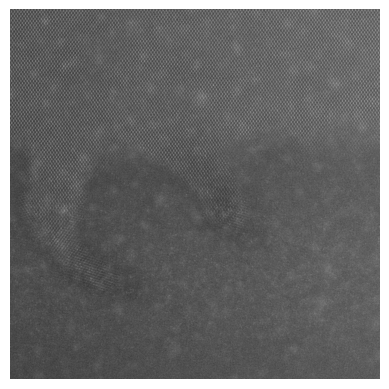

In [24]:
plt.imshow(sisb_images[4], cmap = "grey")
plt.axis("off")

(np.float64(-0.5), np.float64(2047.5), np.float64(2047.5), np.float64(-0.5))

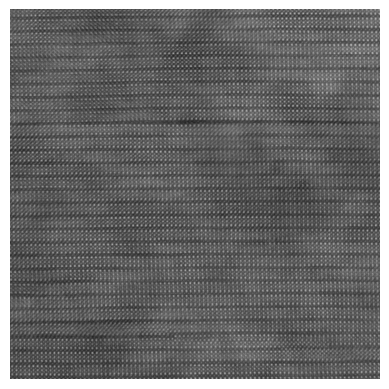

In [26]:
plt.imshow(ybco_images[4], cmap = "grey")
plt.axis("off")